# 04 Clustering: customer types

In this notebook, we group customers by their April-September behaviour and use the groups to test the
performance metric, rather than to improve the model. In 2012, Bijak & Thomas found that splitting credit customers
into segments did not considerably improve prediction (`../research/03-clustering.md`). What clusters can do is give
us different types of customer for the two checks in the plan (`01-plan.ipynb`, section 3):

1. The metric within each cluster, as an overall result can hide poor results within groups.
2. Leaving one cluster out, to see whether the model can handle a type of customer it has never seen. This is the
   brief's "leave out some types of data and observe your performance".

The clusters are a tool rather than true groups, so the number of clusters K is something we vary to check whether
the conclusions depend on it. We also compare k-means with a Gaussian mixture chosen by BIC.

To avoid leakage, the clusters are learned from the training customers only, and the validation customers are
assigned to the nearest cluster centre. The October label is never used to build the clusters, only to describe them
afterwards.

The clustering uses scikit-learn (`KMeans`, `GaussianMixture`, `PCA`, `silhouette_score`, `adjusted_rand_score`),
following its examples on choosing the number of clusters, and SciPy's `bootstrap` for the intervals.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import bootstrap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, roc_auc_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

import prep

wide = prep.load_split()
feats = {part: prep.customer_features(df) for part, df in wide.items()}
scaler = StandardScaler().fit(feats["train"])                 # learned from training customers only
Z = {part: pd.DataFrame(scaler.transform(f), index=f.index, columns=f.columns) for part, f in feats.items()}
feats["train"].describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
mean_util,0.37,0.35,-0.14,1.50
util_change,0.10,0.29,-1.50,1.53
months_behind,0.84,1.56,0.00,6.00
worst_status,0.69,1.09,0.00,8.00
months_inactive,0.82,1.80,0.00,6.00
mean_payratio,0.41,0.40,0.00,1.00
log_limit,11.67,0.94,9.21,13.59
age,35.50,9.24,21.00,79.00


## 1. Features

Each customer gets one row, using April to September only (`prep.customer_features`). The features are mean
utilisation, change in utilisation, months behind, worst status, months inactive (status `-2`, which is thought to
mean no spending), mean payment ratio, log limit and age. Each one is standardised using the training mean and
standard deviation, as k-means uses distances and would otherwise be dominated by the feature with the largest scale.

## 2. The hazard model, to score within clusters

This is the logit hazard from notebook 03, fitted once on all of the training customers.

In [2]:
pm = prep.person_months(wide)
train, val = pm["train"], pm["validation"]


def fit_logit(data):
    """The logit hazard of 03 (only predictions are used here, so no clustered errors)."""
    return sm.GLM(data["event"], sm.add_constant(data[prep.features(data)]), family=sm.families.Binomial()).fit()


def predict_october(model, data):
    rows = prep.october(data)
    return pd.Series(np.asarray(model.predict(sm.add_constant(rows[prep.features(rows)], has_constant="add"))),
                     index=rows.index)


model = fit_logit(train)
y_val = prep.october(val)["event"]
p_val = predict_october(model, val)
print("overall validation AUC:", round(roc_auc_score(y_val, p_val), 4))

overall validation AUC: 0.7438


## 3. How many clusters? Trying a range of K

For each K, the table shows the silhouette score (Rousseeuw, 1987, on a sample of 5,000 customers - higher means the
clusters are better separated), the size of the smallest cluster, and the two things we actually use the clusters
for. These are the range of the hazard model's AUC across the clusters, and the largest drop in AUC when a cluster is
left out. If these barely change with K, the choice of K does not matter for our conclusions.

In [3]:
def kmeans(k):
    return KMeans(n_clusters=k, n_init=20, random_state=prep.SEED).fit(Z["train"])


def leave_one_cluster_out(train_cluster, val_cluster, k):
    """AUC on each cluster's validation customers, with and without that cluster in training."""
    rows = []
    for c in range(k):
        without_c = fit_logit(train[(train_cluster.loc[train.index] != c).to_numpy()])
        in_c = (val_cluster == c).to_numpy()
        rows.append({"cluster": c, "AUC, in training": roc_auc_score(y_val[in_c], p_val[in_c]),
                     "AUC, left out": roc_auc_score(y_val[in_c], predict_october(without_c, val)[in_c])})
    out = pd.DataFrame(rows).set_index("cluster")
    out["change"] = out["AUC, left out"] - out["AUC, in training"]
    return out


sensitivity = []
for k in range(2, 9):
    km = kmeans(k)
    c_train = pd.Series(km.labels_, index=Z["train"].index)
    c_val = pd.Series(km.predict(Z["validation"]), index=Z["validation"].index).loc[y_val.index]
    loco = leave_one_cluster_out(c_train, c_val, k)
    sensitivity.append({"K": k,
                        "silhouette": silhouette_score(Z["train"], km.labels_, sample_size=5000, random_state=prep.SEED),
                        "smallest cluster": int(np.bincount(km.labels_).min()),
                        "lowest AUC in a cluster": loco["AUC, in training"].min(),
                        "highest AUC in a cluster": loco["AUC, in training"].max(),
                        "largest drop when left out": loco["change"].min()})
sensitivity = pd.DataFrame(sensitivity).set_index("K")
sensitivity.round(3)

,silhouette,smallest cluster,lowest AUC in a cluster,highest AUC in a cluster,largest drop when left out
K,,,,,
2,0.242,7612,0.634,0.780,-0.051
3,0.263,4367,0.623,0.745,-0.015
4,0.252,2477,0.616,0.744,-0.008
5,0.246,2419,0.636,0.745,-0.016
6,0.240,1521,0.614,0.727,-0.015
7,0.235,1924,0.621,0.698,-0.059
8,0.234,1788,0.622,0.705,-0.060


## 4. k-means against a Gaussian mixture

A Gaussian mixture model (GMM) allows oval-shaped clusters and gives each customer a probability of belonging to
each cluster. It is fitted by expectation-maximisation (EM), and k-means is the special case where all the clusters
are round and the same size. BIC is used to choose the number of clusters. Some of the features are counts (months
behind, months inactive), which can make some clusters very narrow, so a small `reg_covar` is added to keep the fit
stable. The adjusted Rand index compares each GMM with k-means at the same K, where 1 means the two groupings are
identical and 0 means they are no more alike than chance.

In [4]:
gmm_rows = []
for k in range(2, 9):
    gmm = GaussianMixture(n_components=k, covariance_type="full", reg_covar=1e-3, n_init=3,
                          random_state=prep.SEED).fit(Z["train"])
    gmm_rows.append({"K": k, "BIC": gmm.bic(Z["train"]),
                     "agreement with k-means (ARI)": adjusted_rand_score(kmeans(k).labels_, gmm.predict(Z["train"]))})
gmm_table = pd.DataFrame(gmm_rows).set_index("K")
print("K with the lowest BIC:", gmm_table["BIC"].idxmin())
gmm_table.round(3)

K with the lowest BIC: 8


,BIC,agreement with k-means (ARI)
K,,
2,241471.744,0.705
3,127849.124,0.557
4,92122.485,0.442
5,76333.039,0.403
6,62436.980,0.383
7,50079.910,0.321
8,33323.159,0.328


We also try k-means on the top principal components instead of the raw features (spectral clustering).

In [5]:
pca = PCA(random_state=prep.SEED).fit(Z["train"])
print("variance explained by each component:", pca.explained_variance_ratio_.round(3))
top = pca.transform(Z["train"])[:, :3]
spectral = KMeans(n_clusters=5, n_init=20, random_state=prep.SEED).fit(top)
print("agreement of k-means on 3 PCs with k-means on all features (K = 5, ARI):",
      round(adjusted_rand_score(kmeans(5).labels_, spectral.labels_), 3))

variance explained by each component: [0.357 0.197 0.128 0.118 0.088 0.066 0.024 0.021]


agreement of k-means on 3 PCs with k-means on all features (K = 5, ARI): 0.469


## 5. The clusters at K = 5

K = 5 gives clusters that are easy to describe, and section 3 shows how much this choice matters. The October
default rate is only shown to describe the clusters, it was not used to build them.

In [6]:
K = 5
km = kmeans(K)
cluster = {"train": pd.Series(km.labels_, index=Z["train"].index),
           "validation": pd.Series(km.predict(Z["validation"]), index=Z["validation"].index)}
profile = feats["train"].groupby(cluster["train"]).mean()
profile["customers"] = cluster["train"].value_counts().sort_index()
profile["default rate (Oct)"] = wide["train"][prep.Y].groupby(cluster["train"]).mean()
profile.round(2)

,mean_util,util_change,months_behind,worst_status,months_inactive,mean_payratio,log_limit,age,customers,default rate (Oct)
0,0.05,-0.00,0.31,0.41,0.33,0.79,12.14,36.01,4571,0.15
1,0.56,0.05,0.04,0.07,0.01,0.09,11.77,34.88,4967,0.11
2,0.02,0.02,0.29,0.29,5.07,0.98,12.14,36.71,2419,0.18
3,0.60,-0.00,3.33,2.35,0.03,0.10,11.03,34.69,3607,0.51
4,0.59,0.66,0.32,0.42,0.32,0.24,11.04,35.79,2433,0.20


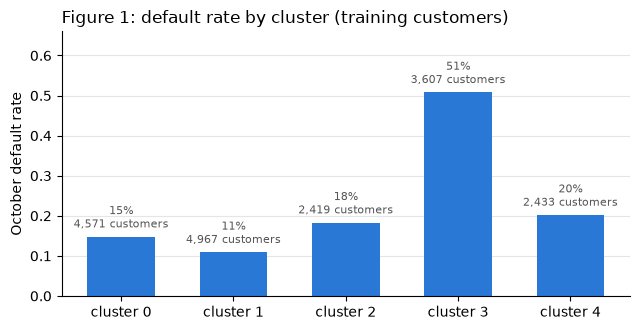

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(profile.index, profile["default rate (Oct)"], width=0.6, color="#2a78d6")
for c, (rate, n) in profile[["default rate (Oct)", "customers"]].iterrows():
    ax.annotate(f"{rate:.0%}\n{int(n):,} customers", (c, rate), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, color="#555555")
ax.set_xticks(profile.index, [f"cluster {c}" for c in profile.index])
ax.set_ylabel("October default rate")
ax.set_ylim(0, profile["default rate (Oct)"].max() * 1.3)
ax.set_title("Figure 1: default rate by cluster (training customers)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 6. The metric within each cluster

This is the hazard model's AUC on the validation customers in each cluster. Within a cluster, the part of the
overall AUC that comes from telling the clusters apart is removed. The 95% interval is a bootstrap over customers,
keeping each customer's label and prediction together.

In [8]:
def bootstrap_auc(y, p):
    ci = bootstrap((y.to_numpy(), p.to_numpy()), roc_auc_score, paired=True, vectorized=False,
                   n_resamples=500, method="percentile", random_state=prep.SEED).confidence_interval
    return ci.low, ci.high


c_val = cluster["validation"].loc[y_val.index]
rows = []
for c in range(K):
    y_c, p_c = y_val[c_val == c], p_val[c_val == c]
    low, high = bootstrap_auc(y_c, p_c)
    rows.append({"cluster": c, "customers": len(y_c), "default rate": y_c.mean(),
                 "AUC": roc_auc_score(y_c, p_c), "95% low": low, "95% high": high})
within = pd.DataFrame(rows).set_index("cluster")
within.round(3)

,customers,default rate,AUC,95% low,95% high
cluster,,,,,
0,1602,0.143,0.653,0.616,0.691
1,1646,0.113,0.636,0.592,0.677
2,762,0.196,0.638,0.585,0.688
3,1199,0.510,0.745,0.720,0.771
4,790,0.192,0.660,0.609,0.714


## 7. Leave one cluster out

Here, we refit the hazard model without one cluster's training customers, then score that cluster's validation
customers, which are a type of customer the model has never seen. The same loop would work for Oscar's and Louis's
models, as long as their fitting code is written as a function.

In [9]:
leave_one_cluster_out(cluster["train"], c_val, K).round(4)

,"AUC, in training","AUC, left out",change
cluster,,,
0,0.6530,0.6583,0.0052
1,0.6358,0.6201,-0.0158
2,0.6381,0.6304,-0.0076
3,0.7447,0.7363,-0.0084
4,0.6604,0.6596,-0.0008


## 8. What this shows

These results come from the run saved in this notebook, which is seeded so it gives the same numbers each time.

* Within clusters, the hazard model ranks customers much less well than it does overall (section 6). The AUC is
  0.64 to 0.66 in four of the five clusters, and 0.75 only in the high-risk cluster (51% default), compared with
  0.74 overall. So a lot of the overall AUC comes from telling the types of customer apart, and a single overall AUC
  makes the model look better than it is for most customers.
* This does not depend on K (section 3). For every K from 2 to 8, the weakest cluster's AUC is between 0.61 and 0.64.
* For a moderate K, an unseen type of customer costs little (section 7). Leaving a cluster out lowers its AUC by at
  most 0.016 for K = 3 to 6. At K = 2, 7 and 8 the largest drop is 0.05 to 0.06, so this result does depend on K -
  when the group left out is very large or very specific, the model generalises less well. This needs to be
  reported with that caveat.
* The silhouette score is low for every K (0.23 to 0.26, best at K = 3). The customers form more of a continuum than
  separate groups, so the clusters are a convenient way of splitting the data rather than natural types.
* The GMM does not settle K either (section 4). Its BIC keeps falling up to K = 8, as the count features let it fit
  very narrow clusters, and it only agrees moderately with k-means (adjusted Rand index 0.4 at K = 5). BIC is good
  for choosing between GMMs, but it does not tell us whether a GMM suits the data in the first place. k-means on the
  top three principal components also only agrees moderately (0.47).